# Практична робота №18
## Множинна лінійна регресія: відбір предикторів, інтерпретація коефіцієнтів, діагностика залишків

**Студент:** Панасюк Дмитро  
**Номер за списком:** 15  
**Варіант:** №5 — **Дніпро** (регіон: Схід)  
**Середньорічна температура:** 10,0 °C  
**Сезонна амплітуда:** 14 °C  
**Базова вологість:** 70 %

**Мета:** побудувати дві множинні регресійні моделі для синтетичних місячних витрат на опалення, інтерпретувати коефіцієнти, перевірити мультиколінеарність за VIF, порівняти R² і adjusted R², дослідити залишки й порівняти з простою регресією **на тих самих спостереженнях**.

*Усі дані навчальні, синтетичні. Витрати вказані в умовних одиницях (ум. од.); не слід трактувати їх як реальні рахунки за опалення.*

## Підготовка. Генерація набору даних `heating`

Використовуємо **точно алгоритм із методичних вказівок**, фіксоване `np.random.seed(42)` та параметри варіанта №5. Кожен рядок — один із 12 місяців.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from scipy import stats
from statsmodels.stats.outliers_influence import variance_inflation_factor
from IPython.display import display

np.random.seed(42)
city = "Дніпро"
mean_temp = 10.0
amplitude = 14.0
hum_base = 70.0

rows = []
for month in range(1, 13):
    temp = mean_temp + amplitude * np.cos((month - 7) / 12 * 2 * np.pi) + np.random.normal(0, 1.0)
    humidity = hum_base + np.random.normal(0, 5.0)
    if temp < 8:
        opal_days = 30
    elif temp < 12:
        opal_days = 15
    else:
        opal_days = 0

    cost = (
        200
        - 9.0 * temp
        + 0.6 * humidity
        + 2.5 * opal_days
        + np.random.normal(0, 15)
    )
    rows.append({
        "місто": city,
        "місяць": month,
        "температура": round(temp, 1),
        "вологість": round(humidity, 1),
        "опалювальні_дні": opal_days,
        "витрати_на_опалення": round(cost, 1),
    })

heating = pd.DataFrame(rows)
assert heating.shape == (12, 6)
print("Набір heating, форма:", heating.shape)
display(heating)

Набір heating, форма: (12, 6)


,місто,місяць,температура,вологість,опалювальні_дні,витрати_на_опалення
0,Дніпро,1,-3.5,69.3,30,357.8
1,Дніпро,2,-0.6,68.8,30,318.2
2,Дніпро,3,4.6,73.8,30,271.0
3,Дніпро,4,10.5,67.7,15,176.2
4,Дніпро,5,17.2,60.4,0,55.2
5,Дніпро,6,21.6,64.9,0,49.6
6,Дніпро,7,23.1,62.9,0,51.9
7,Дніпро,8,21.9,70.3,0,23.7
8,Дніпро,9,16.5,70.6,0,77.0
9,Дніпро,10,10.4,67.0,15,179.9


## Завдання 1. Модель з двома предикторами

Залежна змінна: `витрати_на_опалення`. Предиктори: `температура` і `вологість`. Використовуємо `sm.add_constant()` для вільного члена (intercept) та оцінюємо модель методом найменших квадратів (`sm.OLS`).

In [2]:
y = heating["витрати_на_опалення"]
X2 = sm.add_constant(heating[["температура", "вологість"]])
model2 = sm.OLS(y, X2).fit()

print(model2.summary())
print(f"\nR² = {model2.rsquared:.6f}")
print(f"Adjusted R² = {model2.rsquared_adj:.6f}")
print("Формула:")
print(f"Витрати ≈ {model2.params['const']:.3f} "
      f"{model2.params['температура']:+.3f} × температура "
      f"{model2.params['вологість']:+.3f} × вологість")

                             OLS Regression Results                            
Dep. Variable:     витрати_на_опалення   R-squared:                       0.976
Model:                             OLS   Adj. R-squared:                  0.970
Method:                  Least Squares   F-statistic:                     179.6
Date:                 Tue, 13 Oct 2026   Prob (F-statistic):           5.58e-08
Time:                         14:24:57   Log-Likelihood:                -52.453
No. Observations:                   12   AIC:                             110.9
Df Residuals:                        9   BIC:                             112.4
Df Model:                            2                                         
Covariance Type:             nonrobust                                         
                  coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------
const         227.0031    116.564      1

**Результат.** Модель має **R² = 0,9756** і **adjusted R² = 0,9701**. Рівняння на отриманих синтетичних даних:

**Прогноз витрат (ум. од.) ≈ 227,003 − 12,283 × температура (°C) + 1,148 × вологість (%)**.

Вільний член — формальний прогноз за нульових значень обох предикторів, що не відповідає типовим спостереженням у наборі (зокрема, 0% вологості тут не зустрічається). Його не слід буквально тлумачити як реальні витрати.

## Завдання 2. Інтерпретація коефіцієнтів «за інших рівних умов»

Для кожного коефіцієнта розглядаємо його одиниці, напрямок ефекту та **окрему** перевірку H₀: β = 0 за рівня значущості α = 0,05.

In [3]:
coef_summary = pd.DataFrame({
    "коефіцієнт": model2.params,
    "p-value": model2.pvalues,
    "статистично_значущий_при_0.05": model2.pvalues < 0.05,
})
display(coef_summary.round(6))

,коефіцієнт,p-value,статистично_значущий_при_0.05
const,227.003065,0.083308,False
температура,-12.282897,0.000000,True
вологість,1.148312,0.493621,False


**Температура:** за **незмінної вологості** підвищення середньомісячної температури на **1 °C** пов'язане зі **зменшенням очікуваних витрат приблизно на 12,283 ум. од.** Коефіцієнт статистично значущий (p ≈ 1,29 × 10⁻⁷ < 0,05). Від'ємний знак узгоджується з меншою потребою в опаленні у теплі місяці.

**Вологість:** за **незмінної температури** підвищення відносної вологості на **1 процентний пункт** пов'язане зі **збільшенням очікуваних витрат приблизно на 1,148 ум. од.** Але p ≈ 0,4936 > 0,05, отже за цією малою вибіркою немає достатніх підстав стверджувати, що її частковий коефіцієнт відмінний від нуля. Це **не доводить**, що впливу вологості немає взагалі.

У генераторі витрат прямо використані також `опалювальні_дні`, поки що пропущені в моделі. Тому оцінені коефіцієнти двопредикторної моделі не обов'язково дорівнюють коефіцієнтам формули генерації.

## Завдання 3. Перевірка мультиколінеарності через VIF

VIF обчислюємо **тільки для предикторів** (константу пропускаємо). Орієнтири з умови: VIF > 5 — увага, VIF > 10 — серйозна проблема.

In [4]:
vif2 = pd.DataFrame({
    "предиктор": [col for col in X2.columns if col != "const"],
    "VIF": [
        variance_inflation_factor(X2.values, X2.columns.get_loc(col))
        for col in X2.columns if col != "const"
    ]
})
display(vif2.round(4))
print("Кореляція температури й вологості:",
      round(heating["температура"].corr(heating["вологість"]), 4))

,предиктор,VIF
0,температура,1.553
1,вологість,1.553


Кореляція температури й вологості: -0.5967


**Висновок за VIF.** Для температури та вологості **VIF ≈ 1,553** — нижче порогів 5 і 10, отже критичної мультиколінеарності в двопредикторній моделі **не виявлено**. Кореляція цих предикторів дорівнює приблизно −0,597: зв'язок є, але він не настільки сильний, щоб спричинити високий VIF.

Це очікувано: температура створена через сезонну косинусоїду, а вологість — окремим випадковим відхиленням навколо 70%, **без прямого включення температури у формулу генерації вологості**. На 12 випадкових значеннях певна кореляція може виникнути, але жорсткої залежності немає.

## Завдання 4. Третій предиктор: R² проти adjusted R²

Створюємо другу модель з `опалювальні_дні`. Оскільки дні опалення визначаються порогами температури (менше 8 °C, від 8 до 12 °C та понад 12 °C), перевіряємо не тільки якість підгонки, а й VIF.

In [5]:
X3 = sm.add_constant(heating[["температура", "вологість", "опалювальні_дні"]])
model3 = sm.OLS(y, X3).fit()

compare_models = pd.DataFrame({
    "модель": ["2 предиктори", "3 предиктори"],
    "кількість_предикторів": [2, 3],
    "R²": [model2.rsquared, model3.rsquared],
    "adjusted_R²": [model2.rsquared_adj, model3.rsquared_adj],
})
print(model3.summary())
print("\nПорівняння моделей:")
display(compare_models.round(6))
print(f"Приріст R²: {model3.rsquared - model2.rsquared:+.6f}")
print(f"Приріст adjusted R²: {model3.rsquared_adj - model2.rsquared_adj:+.6f}")

                             OLS Regression Results                            
Dep. Variable:     витрати_на_опалення   R-squared:                       0.992
Model:                             OLS   Adj. R-squared:                  0.988
Method:                  Least Squares   F-statistic:                     314.0
Date:                 Tue, 13 Oct 2026   Prob (F-statistic):           1.23e-08
Time:                         14:24:57   Log-Likelihood:                -46.060
No. Observations:                   12   AIC:                             100.1
Df Residuals:                        8   BIC:                             102.1
Df Model:                            3                                         
Covariance Type:             nonrobust                                         
                      coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------------------------------------------------
const             231.0697     7

,модель,кількість_предикторів,R²,adjusted_R²
0,2 предиктори,2,0.975556,0.970124
1,3 предиктори,3,0.991579,0.988421


Приріст R²: +0.016023
Приріст adjusted R²: +0.018297


In [6]:
vif3 = pd.DataFrame({
    "предиктор": [col for col in X3.columns if col != "const"],
    "VIF": [
        variance_inflation_factor(X3.values, X3.columns.get_loc(col))
        for col in X3.columns if col != "const"
    ]
})
print("VIF після додавання опалювальних днів:")
display(vif3.round(4))
print("Кореляція температура / опалювальні дні:",
      round(heating["температура"].corr(heating["опалювальні_дні"]), 4))

VIF після додавання опалювальних днів:


,предиктор,VIF
0,температура,13.4096
1,вологість,1.8985
2,опалювальні_дні,15.6179


Кореляція температура / опалювальні дні: -0.9601


**Висновок.** Додавання третього предиктора підвищило **R² з 0,9756 до 0,9916**, а **adjusted R² з 0,9701 до 0,9884**. Отже, навіть після штрафу за додатковий параметр новий предиктор покращив опис цих навчальних даних.

Проте **VIF температури ≈ 13,41, VIF опалювальних днів ≈ 15,62** (вологість ≈ 1,90). Це серйозна мультиколінеарність: кореляція температури та кількості опалювальних днів приблизно **−0,960**, що прямо випливає з порогової формули їх формування. Через це **окремі коефіцієнти трипредикторної моделі можуть бути нестійкими**, хоча загальна якість підгонки вища.

Для **опису наявної вибірки** модель із трьома предикторами краща за adjusted R²; для **стійкої інтерпретації незалежних ефектів** обережніше ставитися до колінеарної пари (температура/дні) та не вважати складнішу модель безумовно кращою. Для реального прогнозування знадобилися б додаткові спостереження й перевірка на нових даних.

## Завдання 5. Діагностика залишків двопредикторної моделі

Досліджуємо саме **`model2`**, як вимагає завдання. Залишок = фактичне значення мінус передбачене. Перевіряємо візуально форму розкиду, а також нормальність за QQ-plot і критерієм Шапіро—Вілка.

,місяць,температура_°C,факт,прогноз,залишок
0,1,-3.5,357.8,349.57,8.23
1,2,-0.6,318.2,313.38,4.82
2,3,4.6,271.0,255.25,15.75
3,4,10.5,176.2,175.77,0.43
4,5,17.2,55.2,85.10,-29.90
5,6,21.6,49.6,36.22,13.38
6,7,23.1,51.9,15.50,36.40
7,8,21.9,23.7,38.73,-15.03
8,9,16.5,77.0,105.41,-28.41
9,10,10.4,179.9,176.20,3.70


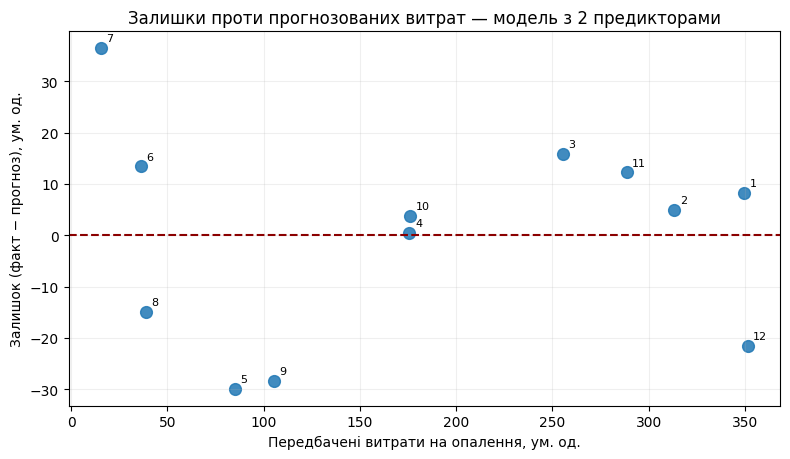

In [7]:
diagnostics = pd.DataFrame({
    "місяць": heating["місяць"],
    "температура_°C": heating["температура"],
    "факт": y,
    "прогноз": model2.fittedvalues,
    "залишок": model2.resid,
})
display(diagnostics.round(2))

fig, ax = plt.subplots(figsize=(8, 4.7))
ax.scatter(model2.fittedvalues, model2.resid, s=72, alpha=0.85)
ax.axhline(0, color="darkred", linestyle="--", linewidth=1.5)
for month, fitted, resid in zip(heating["місяць"], model2.fittedvalues, model2.resid):
    ax.annotate(str(month), (fitted, resid), xytext=(4, 5),
                textcoords="offset points", fontsize=8)
ax.set_xlabel("Передбачені витрати на опалення, ум. од.")
ax.set_ylabel("Залишок (факт − прогноз), ум. од.")
ax.set_title("Залишки проти прогнозованих витрат — модель з 2 предикторами")
ax.grid(alpha=0.2)
fig.tight_layout()
plt.show()

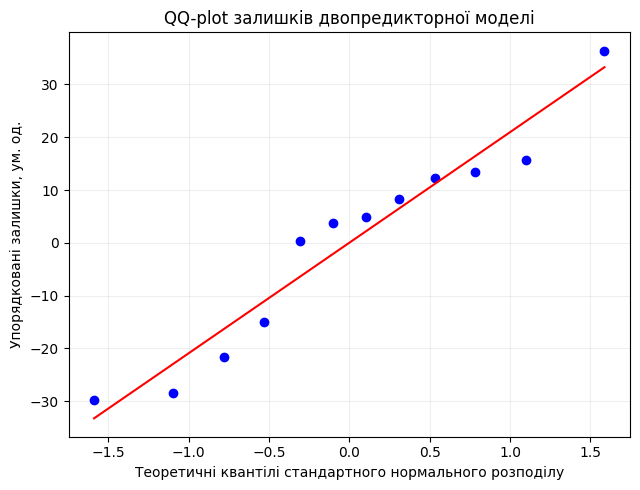

Шапіро—Вілк: W=0.938813, p-value=0.482848
Рішення для α=0.05: не відхиляємо H0 нормальності


In [8]:
fig, ax = plt.subplots(figsize=(6.5, 5))
stats.probplot(model2.resid, dist="norm", plot=ax)
ax.set_title("QQ-plot залишків двопредикторної моделі")
ax.set_xlabel("Теоретичні квантілі стандартного нормального розподілу")
ax.set_ylabel("Упорядковані залишки, ум. од.")
ax.grid(alpha=0.2)
fig.tight_layout()
plt.show()

shapiro_result = stats.shapiro(model2.resid)
print(f"Шапіро—Вілк: W={shapiro_result.statistic:.6f}, p-value={shapiro_result.pvalue:.6f}")
print("Рішення для α=0.05:", "відхиляємо H0 нормальності"
      if shapiro_result.pvalue < 0.05 else "не відхиляємо H0 нормальності")

**Аналіз графіка залишків.** Залишки лежать по обидва боки від нуля. У діапазоні менших прогнозованих витрат, який здебільшого відповідає теплим місяцям, видно порівняно великі як **від'ємні** залишки (травень ≈ −29,90; вересень ≈ −28,41), так і **додатний** (липень ≈ +36,40). Для місяців із великими прогнозними витратами залишки загалом менш розкидані, але **чіткої стійкої лійки на 12 точках не видно**. Наявний натяк на неоднаковий розкид варто перевіряти на більшій вибірці, а не проголошувати гетероскедастичність доведеною.

У генераторі витрат важливі порогові `опалювальні_дні` (0/15/30), а ця двопредикторна модель їх не включає. Тому помітні відхилення, особливо біля переходів між опалювальним і неопалювальним періодами, можуть відображати **пропущену нелінійну/ступінчасту складову**. Високий R² сам собою цього не виключає.

**QQ-plot і тест Шапіро—Вілка:** W ≈ **0,9388**, **p ≈ 0,4828 > 0,05**. На рівні значущості 0,05 **немає підстав відхиляти нормальність залишків**; це не означає, що нормальність доведено, особливо за n = 12. Точки QQ-plot здебільшого слідують опорній прямій з певними відхиленнями у хвостах.

## Завдання 6. Порівняння з простою регресією

**Уточнення щодо Практики 17:** там застосовувався **інший синтетичний набір `climate`** і інша формула витрат. Тому безпосередньо порівнювати R² із того файлу та adjusted R² для `heating` методологічно некоректно: змінюється залежна змінна та її дисперсія. Для коректного порівняння **повторно оцінюємо модель лише з температурою на цьому самому `heating`** й однакових 12 спостереженнях.

In [9]:
X1 = sm.add_constant(heating[["температура"]])
model1 = sm.OLS(y, X1).fit()

comparison = pd.DataFrame({
    "модель": ["Проста: температура", "Множинна: температура + вологість"],
    "R²": [model1.rsquared, model2.rsquared],
    "adjusted_R²": [model1.rsquared_adj, model2.rsquared_adj],
})
display(comparison.round(6))
print(f"Приріст R² при додаванні вологості: {model2.rsquared - model1.rsquared:.6f}")
print(f"Зміна adjusted R²: {model2.rsquared_adj - model1.rsquared_adj:+.6f}")
print(f"p-value вологості в повній моделі: {model2.pvalues['вологість']:.6f}")

,модель,R²,adjusted_R²
0,Проста: температура,0.974173,0.971591
1,Множинна: температура + вологість,0.975556,0.970124


Приріст R² при додаванні вологості: 0.001383
Зміна adjusted R²: -0.001467
p-value вологості в повній моделі: 0.493621


**Висновок за порівнянням.** Проста модель на `heating` має **R² ≈ 0,9742**. Додавання вологості збільшує R² лише до **0,9756** (плюс **0,00138**, або близько **0,14 відсоткового пункта** поясненої дисперсії). Натомість **adjusted R² знижується з 0,9716 до 0,9701**, бо мінімальне поліпшення підгонки не компенсує штраф за зайвий параметр на 12 рядках.

Це узгоджується з великим p-value вологості (≈ 0,4936): її додаткова пояснювальна користь за врахування температури тут мала. МНК ніколи не збільшує суму квадратів залишків після додавання регресора, тому звичайний R² зростає або лишається незмінним, навіть якщо новий регресор практично неінформативний.

## Контрольні питання — письмові відповіді

**1. Чому `sm.add_constant()` потрібен перед `sm.OLS()`?**  
`statsmodels.OLS()` **не додає константу автоматично**. `sm.add_constant(X)` створює стовпець одиниць, щоб модель могла оцінити вільний член β₀. Якщо його пропустити, регресійна площина буде примусово проходити через початок координат (нульові предиктори → нульовий прогноз), що для витрат на опалення не обґрунтовано та може спотворити коефіцієнти й якість моделі.

**2. Чим коефіцієнт множинної регресії відрізняється від коефіцієнта простої?**  
У простій регресії коефіцієнт температури описує загальний лінійний зв'язок із витратами **без контролю інших змінних**. У множинній регресії температурний коефіцієнт описує очікувану зміну витрат при +1 °C **за фіксованої вологості**. Тому він може мати інше числове значення, оскільки частина спільної з іншими факторами варіації враховується окремо.

**3. Чому звичайний R² не зменшується після додавання нового предиктора і навіщо adjusted R²?**  
У звичайному МНК стара модель вкладена в нову: новий коефіцієнт можна обрати рівним нулю, відтворивши стару підгонку. Отже, оптимальна сума квадратів залишків після додавання регресора не може збільшитися, а **R² = 1 − SSE/SST** не може зменшитися за тих самих спостережень і залежної змінної. **Adjusted R²** враховує кількість предикторів та обсяг вибірки й може знизитися, якщо нова змінна не приносить достатнього покращення (як вологість у порівнянні простої та двопредикторної моделей).

**4. Що означають VIF ≈ 1 та VIF > 10?**  
VIF ≈ 1 означає, що предиктор майже не пояснюється лінійною комбінацією решти предикторів, тому його дисперсія оцінювання практично не «роздувається» через колінеарність. **VIF > 10** — сигнал серйозної мультиколінеарності, що ускладнює надійну інтерпретацію окремих коефіцієнтів. Практично слід перевірити логіку включених предикторів, за потреби прибрати один із дублюючих або поєднати/переформулювати ознаки, зібрати більше даних; залежно від задачі також розглянути регуляризацію. У нашій трипредикторній моделі підозріла пара — температура й опалювальні дні.

## Підсумковий висновок

1. Для **Дніпра (варіант №5)** побудовано синтетичні місячні дані та моделі витрат із двома й трьома предикторами.
2. Двопредикторна модель: **R² ≈ 0,9756, adjusted R² ≈ 0,9701**; за незмінної вологості +1 °C пов'язаний із **−12,283 ум. од.** очікуваних витрат; окремий ефект вологості статистично незначущий.
3. У двопредикторній моделі **VIF ≈ 1,55**, а в трипредикторній VIF температури й опалювальних днів **перевищує 10**. Додавання третього предиктора покращує adjusted R², однак ускладнює стійку інтерпретацію коефіцієнтів.
4. Графік залишків потребує уваги до більших відхилень у теплі місяці; **Шапіро—Вілк (p ≈ 0,483)** не дає підстав відхилити нормальність залишків.
5. Додавання вологості до простої температурної моделі майже не змінює R² і трохи погіршує adjusted R²; числове порівняння проведено **на тих самих даних**, що важливо для коректності висновку.

**Усі висновки стосуються лише цього малого навчального набору (12 спостережень), а не реального клімату чи вартості опалення в Дніпрі.**